# Predicting Exam Percentage from Study Habits

Target `exam_percentage` is an ordered band: 0 = below 40%, 1 = 40-49%, 2 = 50-59%, 3 = 60-69%, 4 = 70-79%, 5 = 80-89%, 6 = 90% and above. Each band is about 10 percentage points wide, so an error of 1.0 is about 10 points.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/MSDS 621; Project/"
except ImportError:
    DATA_DIR = "./"   # CSV in the same folder as this notebook

FIG_DIR = DATA_DIR + "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150)
    plt.show()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load data and choose features
Features are the study-habit columns plus education and field (one-hot). The `improvement` columns are left out because they are what students *wish* to improve, not a habit. `timestamp` is left out too.

In [3]:
cl = pd.read_csv(DATA_DIR + "student_study_habits_cleaned.csv")

habit_cols = ["year", "study_hours", "sleep_hours", "attendance", "revision", "exam_prep",
              "social_media", "distraction", "concentration", "assignment_completion", "confidence"]
dummy_cols = [c for c in cl.columns if c.startswith("education_") or c.startswith("field_")]
feature_cols = habit_cols + dummy_cols

X = cl[feature_cols]
y = cl["exam_percentage"]
print("Rows:", len(cl), " Features:", len(feature_cols))
print(y.value_counts().sort_index().to_string())


Rows: 812  Features: 19
exam_percentage
0    128
1    141
2    192
3    158
4    133
5     53
6      7


## 2. Train/test split (80/20)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train rows:", len(X_train), " Test rows:", len(X_test))


Train rows: 649  Test rows: 163


## 3. Compare models
The baseline always predicts the average score. Any real model must beat it.

- **MAE** = average error in bands (1.0 is about 10 points).
- **R2** = share of the variation in exam scores the model explains (0 = no better than the average).
- **Within 1 band** = share of test students whose rounded prediction is at most one band off.
- **CV R2** = R2 averaged over 5 folds, a steadier estimate than one split.

In [5]:
models = {
    "Baseline (average)": DummyRegressor(),
    "Linear regression": LinearRegression(),
    "Decision tree (depth 3)": DecisionTreeRegressor(max_depth=3, random_state=42),
    "Random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({
        "model": name,
        "MAE": round(mean_absolute_error(y_test, pred), 3),
        "R2": round(r2_score(y_test, pred), 3),
        "within 1 band": round((np.abs(np.round(pred) - y_test) <= 1).mean(), 3),
        "CV R2": round(cross_val_score(model, X, y, cv=kf, scoring="r2").mean(), 3),
    })

results = pd.DataFrame(rows)
print(results.to_string(index=False))
results.to_csv(f"{FIG_DIR}/model_comparison.csv", index=False)


                  model   MAE     R2  within 1 band  CV R2
     Baseline (average) 1.162 -0.022          0.699 -0.015
      Linear regression 0.795  0.540          0.896  0.626
Decision tree (depth 3) 0.918  0.327          0.804  0.452
          Random forest 0.792  0.516          0.890  0.588


## 4. Predicted vs actual (random forest)

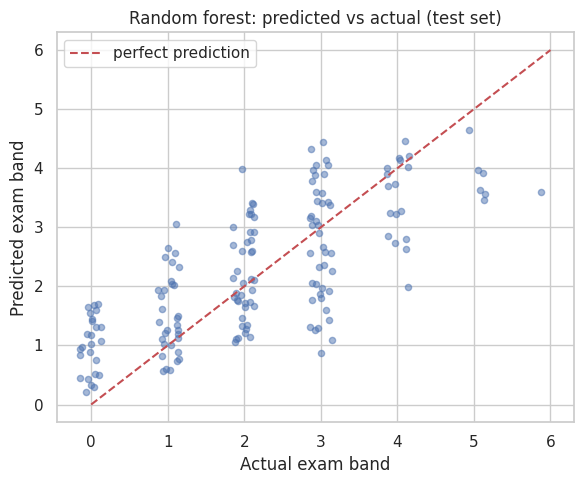

In [6]:
rf = models["Random forest"]
pred = rf.predict(X_test)

rng = np.random.default_rng(0)
plt.figure(figsize=(6, 5))
plt.scatter(y_test + rng.uniform(-0.15, 0.15, len(y_test)), pred, alpha=0.5, s=20)
plt.plot([0, 6], [0, 6], "r--", label="perfect prediction")
plt.xlabel("Actual exam band")
plt.ylabel("Predicted exam band")
plt.title("Random forest: predicted vs actual (test set)")
plt.legend()
save("10_predicted_vs_actual")


## 5. Which habits matter? (feature importance)

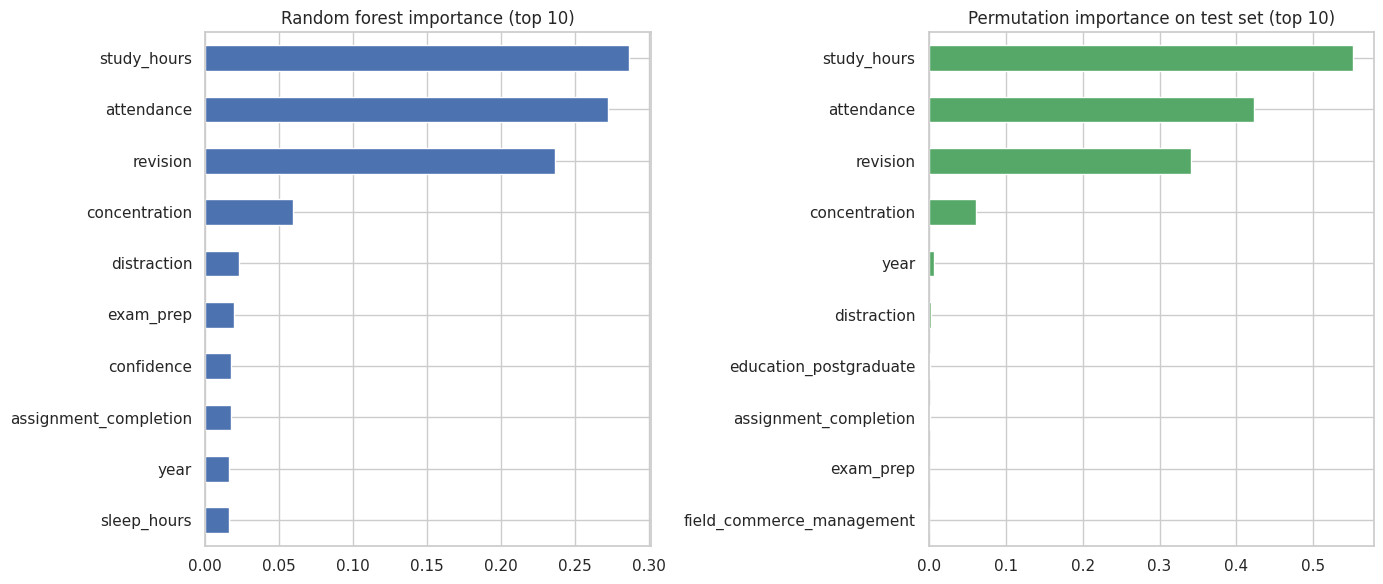

study_hours      0.287
attendance       0.272
revision         0.236
concentration    0.059
distraction      0.023
exam_prep        0.020


In [7]:
imp = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)

perm = permutation_importance(rf, X_test, y_test, n_repeats=20, random_state=42)
perm_imp = pd.Series(perm.importances_mean, index=feature_cols).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
imp.head(10)[::-1].plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("Random forest importance (top 10)")
perm_imp.head(10)[::-1].plot(kind="barh", ax=axes[1], color="#55A868")
axes[1].set_title("Permutation importance on test set (top 10)")
save("11_feature_importance")

print(imp.head(6).round(3).to_string())


## 6. A simple tree you can explain

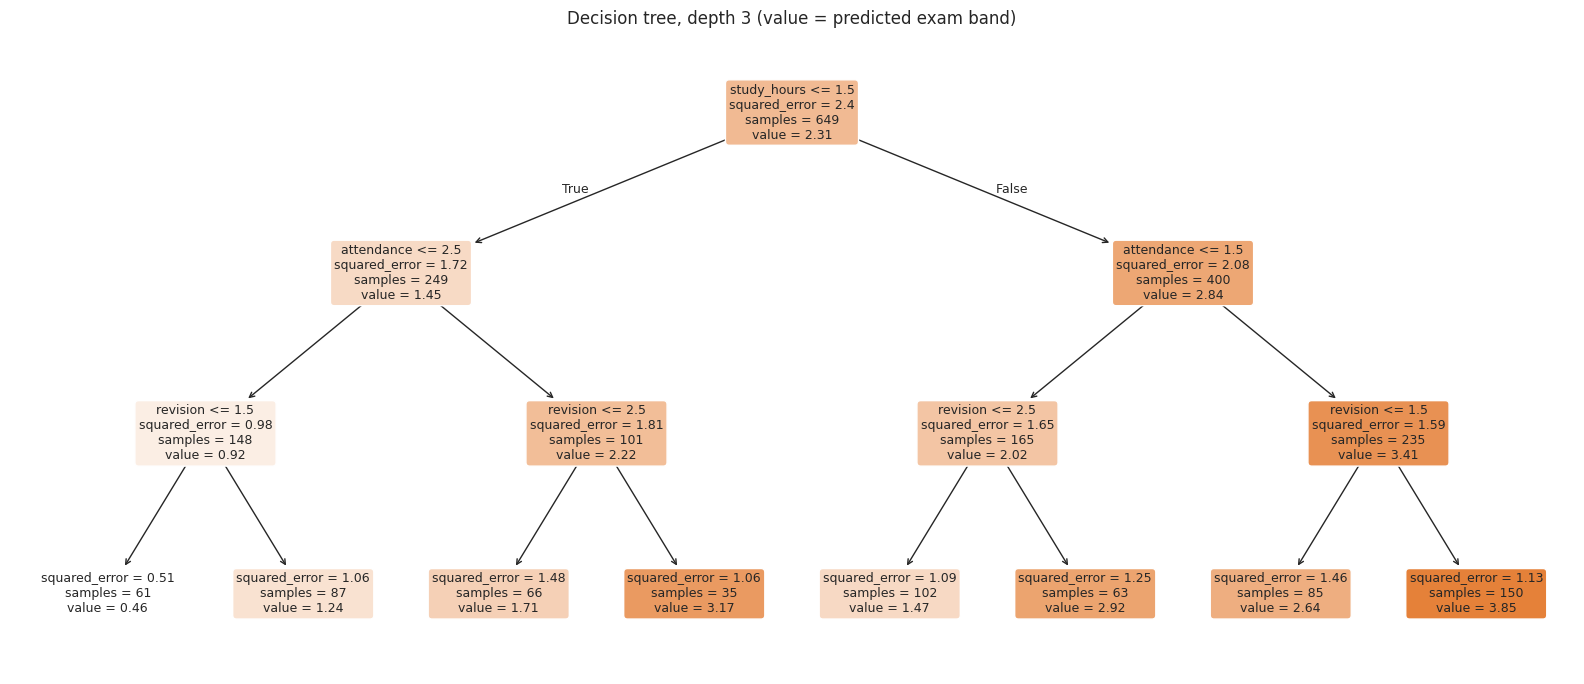

In [8]:
tree = models["Decision tree (depth 3)"]
plt.figure(figsize=(16, 7))
plot_tree(tree, feature_names=feature_cols, filled=True, rounded=True, fontsize=9, precision=2)
plt.title("Decision tree, depth 3 (value = predicted exam band)")
save("12_decision_tree")


## 7. How much do the top habits explain?

In [9]:
top3 = ["study_hours", "attendance", "revision"]
others = [c for c in feature_cols if c not in top3]

def cv_r2(cols):
    m = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42)
    return round(cross_val_score(m, cl[cols], y, cv=kf, scoring="r2").mean(), 3)

print("All features:               ", cv_r2(feature_cols))
print("Only the top 3 habits:      ", cv_r2(top3))
print("Everything except top 3:    ", cv_r2(others))


All features:                0.585
Only the top 3 habits:       0.572
Everything except top 3:     -0.037
